# PYTORCH MASTERY — NOTEBOOK 5
## Chapters 21–25: Learning Rate Schedulers → First Neural Network → Professional Training Loop → Dataset and DataLoader → Custom Datasets

Continuing directly from Notebook 4. This is where every prior piece assembles into your first complete, trainable model.


### PYTORCH MASTERY PROGRESS
Current Chapter: 25 | Current Level: Training Infrastructure

- [x] Chapters 1–20 *(Notebooks 1–4)*
- [x] Learning Rate Schedulers
- [x] First Neural Network
- [x] Professional Training Loop
- [x] Dataset/DataLoader
- [x] Custom Datasets


---
# CHAPTER 21 — LEARNING RATE SCHEDULERS

## 1. Concept
A fixed learning rate throughout training is rarely optimal: a larger LR helps early training make fast progress, while a smaller LR later helps the model settle precisely into a good minimum without overshooting. A **scheduler** adjusts the learning rate according to a predefined pattern as training progresses — distinct from the learning rate *value* itself (a single number) versus the learning rate *schedule* (a function of training progress).

## 2. The Core Schedulers


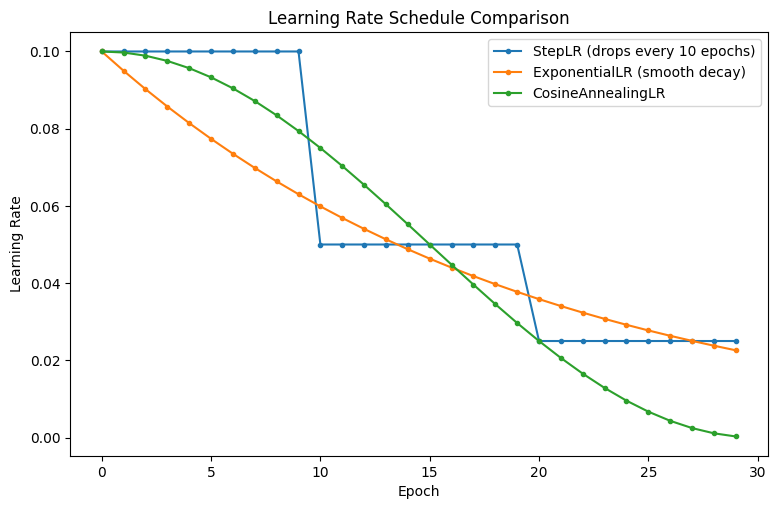

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

model = nn.Linear(10, 1)
base_lr = 0.1

schedulers_to_demo = {
    "StepLR (drops every 10 epochs)": torch.optim.lr_scheduler.StepLR(
        torch.optim.SGD(model.parameters(), lr=base_lr), step_size=10, gamma=0.5),
    "ExponentialLR (smooth decay)": torch.optim.lr_scheduler.ExponentialLR(
        torch.optim.SGD(model.parameters(), lr=base_lr), gamma=0.95),
    "CosineAnnealingLR": torch.optim.lr_scheduler.CosineAnnealingLR(
        torch.optim.SGD(model.parameters(), lr=base_lr), T_max=30),
}

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, scheduler in schedulers_to_demo.items():
    lrs = []
    for epoch in range(30):
        lrs.append(scheduler.get_last_lr()[0])
        scheduler.optimizer.step()   # a dummy step -- normally this is your real training step
        scheduler.step()              # advance the SCHEDULE (usually called once per epoch)
    ax.plot(lrs, label=name, marker="o", markersize=3)

ax.set_xlabel("Epoch")
ax.set_ylabel("Learning Rate")
ax.set_title("Learning Rate Schedule Comparison")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `StepLR(optimizer, step_size=10, gamma=0.5)` — every `step_size` epochs, multiplies the current LR by `gamma` — a simple, "staircase" decay pattern; easy to reason about but requires manually choosing WHEN to drop.
- `ExponentialLR(optimizer, gamma=0.95)` — multiplies the LR by `gamma` **every single call** to `.step()` (typically once per epoch) — a smooth, continuous exponential decay.
- `CosineAnnealingLR(optimizer, T_max=30)` — follows a cosine curve from the initial LR down to (near) zero over `T_max` steps — smoothly decelerating, currently one of the most popular schedules for training from scratch, since the smooth deceleration (rather than an abrupt staircase drop) tends to produce stable, strong final convergence.
- `scheduler.step()` is called **once per epoch** in the typical pattern shown here (not once per batch) — though some schedulers (notably `OneCycleLR`, below) are specifically designed to be stepped once per **batch** instead; always check a given scheduler's documented expected calling frequency.

## 3. `ReduceLROnPlateau` — Reactive, Not Fixed-Schedule


In [ ]:
optimizer_plateau = torch.optim.SGD(model.parameters(), lr=0.1)
plateau_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_plateau, mode="min", factor=0.5, patience=3,
)

# UNLIKE the other schedulers, this one needs a METRIC (usually validation loss) passed to .step()
simulated_val_losses = [1.0, 0.8, 0.75, 0.74, 0.745, 0.746, 0.747, 0.6, 0.55]   # plateaus, then improves
for epoch, val_loss in enumerate(simulated_val_losses):
    plateau_scheduler.step(val_loss)   # note: takes the METRIC, not just called with no args
    current_lr = optimizer_plateau.param_groups[0]["lr"]
    print(f"Epoch {epoch}: val_loss={val_loss}, current LR={current_lr}")


Epoch 0: val_loss=1.0, current LR=0.1
Epoch 1: val_loss=0.8, current LR=0.1
Epoch 2: val_loss=0.75, current LR=0.1
Epoch 3: val_loss=0.74, current LR=0.1
Epoch 4: val_loss=0.745, current LR=0.1
Epoch 5: val_loss=0.746, current LR=0.1
Epoch 6: val_loss=0.747, current LR=0.1
Epoch 7: val_loss=0.6, current LR=0.1
Epoch 8: val_loss=0.55, current LR=0.1


### Line-by-Line Explanation
- `ReduceLROnPlateau` is fundamentally different from the other schedulers: it doesn't follow a predetermined mathematical curve — it **monitors** a metric you pass to `.step(metric)` (almost always validation loss), and reduces the LR by `factor` only after `patience` consecutive epochs show no improvement (`mode="min"` means "improvement" = the metric going down). This makes it genuinely adaptive to your specific training run's actual behavior, rather than a fixed schedule chosen in advance.
- `optimizer.param_groups[0]["lr"]` — the way to actually **inspect** an optimizer's current learning rate; an optimizer can have multiple `param_groups` (Chapter 38's transfer-learning use case, applying different learning rates to different parts of a model), each with its own independent LR.

## 4. `OneCycleLR` — Modern Best Practice for Training From Scratch


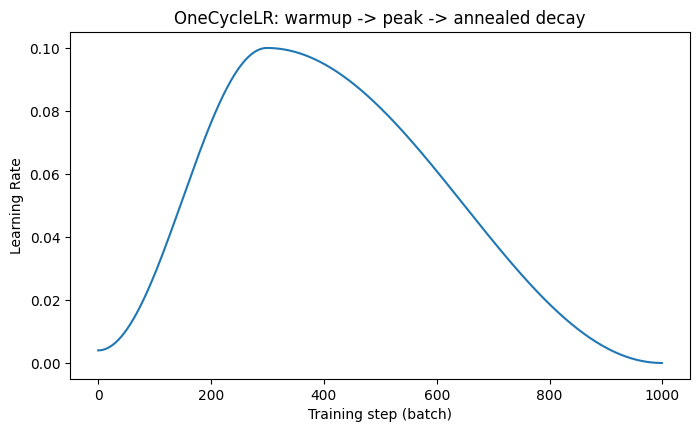

In [ ]:
optimizer_onecycle = torch.optim.SGD(model.parameters(), lr=0.01)
steps_per_epoch = 100
total_epochs = 10

onecycle_scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer_onecycle, max_lr=0.1, steps_per_epoch=steps_per_epoch, epochs=total_epochs,
)

lrs_onecycle = []
for step in range(steps_per_epoch * total_epochs):
    lrs_onecycle.append(onecycle_scheduler.get_last_lr()[0])
    onecycle_scheduler.optimizer.step()
    onecycle_scheduler.step()   # OneCycleLR is stepped ONCE PER BATCH, not once per epoch!

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lrs_onecycle)
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Learning Rate")
ax.set_title("OneCycleLR: warmup -> peak -> annealed decay")
plt.show()


### Warmup — Why Training Often Starts With a LOW Learning Rate That Increases First
`OneCycleLR`'s characteristic shape — a **warmup** phase (LR rises from a small value to `max_lr`), followed by an **annealing** phase (LR decreases, often all the way toward zero) — encodes a genuinely important practical insight: at the very start of training, a model's weights are randomly initialized and its gradients can be poorly-scaled/noisy; a large learning rate applied immediately can cause unstable, diverging updates. A brief warmup period lets the optimizer's internal statistics (for Adam-family optimizers) and the model's weights settle into a more reasonable region before the LR ramps up to its peak, after which the extended annealing phase lets the model converge precisely. Warmup is now standard practice for training Transformers and most modern large-scale architectures (Chapter 57's LLM fine-tuning revisits this directly).

### Common Mistakes
- Calling `scheduler.step()` at the wrong frequency (once per batch when the scheduler expects once per epoch, or vice versa) — `OneCycleLR` in particular is specifically designed for per-batch stepping; using it per-epoch produces a badly distorted, unintended schedule shape.
- Forgetting `ReduceLROnPlateau.step()` needs the actual metric value passed as an argument, unlike every other scheduler here — a common `TypeError`/incorrect-usage source.
- Not verifying the actual applied learning rate via `optimizer.param_groups[0]["lr"]` during debugging — trusting that a scheduler is "probably doing the right thing" without checking is a common source of silently-wrong training runs.

### Interview Insight
**Q: Why might you use a learning rate warmup phase at the start of training, rather than starting directly at your intended peak learning rate?**
A: At the very beginning of training, model weights are randomly initialized and the loss landscape's local gradient information can be poorly representative/noisy — applying a large learning rate immediately risks unstable, oscillating, or outright diverging updates before the model has had any chance to settle into a reasonable region of parameter space. A warmup phase starts with a small learning rate and gradually increases it, letting both the model's weights and (for adaptive optimizers like Adam) the optimizer's internal running statistics stabilize first, before the learning rate reaches its full intended peak — this is now standard, near-universal practice for training Transformers and other modern large architectures.

### Exercise
1. Plot `StepLR` with `step_size=5, gamma=0.1` over 30 epochs and compare its "staircase" shape to `CosineAnnealingLR`'s smooth curve.
2. Simulate a validation loss sequence that genuinely plateaus, and confirm `ReduceLROnPlateau` correctly triggers a reduction after the specified `patience`.

### Quiz (Chapter 21)
1. What's the fundamental difference between `ReduceLROnPlateau` and every other scheduler in this chapter?
2. Why does `OneCycleLR` typically get stepped once per batch rather than once per epoch?
3. What practical problem does a learning-rate warmup phase solve?
4. How do you inspect an optimizer's actual current learning rate?


---
# CHAPTER 22 — FIRST NEURAL NETWORK

## 1. Concept
This chapter assembles every piece from Notebook 4 (nn.Module, layers, activations, loss, optimizer) plus Chapter 21's scheduler into one complete, working classifier — the full workflow:

```
Dataset → DataLoader → Model → Loss → Optimizer → Training Loop → Validation → Evaluation
```

## 2. The Complete Example — a Tabular Binary Classifier


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. DATA -- using sklearn (already mastered) to generate + split + scale, exactly the
#    Scikit-learn course's own workflow, now feeding INTO a PyTorch model instead of a
#    RandomForestClassifier -- a genuine, direct connection between the two courses
X, y = make_classification(n_samples=2000, n_features=20, n_informative=15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on train -- Scikit-learn course Ch 5's lesson, STILL applies
X_test_scaled = scaler.transform(X_test)

# 2. CONVERT to PyTorch tensors -- note the REQUIRED dtypes (Chapter 4/19's lessons)
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.int64)     # int64 for CrossEntropyLoss
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.int64)

# 3. Dataset + DataLoader (full treatment in Chapter 24 -- used here to see it in context first)
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(f"Training samples: {len(train_dataset)}, batches per epoch: {len(train_loader)}")


Training samples: 1600, batches per epoch: 50


In [ ]:
# 4. MODEL
class TabularClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, num_classes),   # raw logits out -- NO softmax (Ch 19's rule)
        )

    def forward(self, x):
        return self.net(x)


model = TabularClassifier(input_dim=20)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters()):,}")


TabularClassifier(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
)

Total trainable parameters: 3,490


In [ ]:
# 5. TRAINING LOOP (full professional version is Chapter 23 -- a straightforward version here)
num_epochs = 20
model.train()   # Chapter 17's lesson: Dropout is ACTIVE during training

for epoch in range(num_epochs):
    epoch_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * X_batch.size(0)

    scheduler.step()
    epoch_loss /= len(train_dataset)
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}  train_loss={epoch_loss:.4f}  lr={scheduler.get_last_lr()[0]:.6f}")


Epoch 5/20  train_loss=0.2601  lr=0.000854
Epoch 10/20  train_loss=0.1529  lr=0.000500
Epoch 15/20  train_loss=0.1291  lr=0.000146
Epoch 20/20  train_loss=0.1291  lr=0.000000


In [ ]:
# 6. EVALUATION
model.eval()   # Dropout becomes a no-op; BatchNorm (if present) uses running stats
with torch.inference_mode():   # Chapter 15's preferred modern choice for pure inference
    test_logits = model(X_test_t)
    test_preds = test_logits.argmax(dim=1)   # Chapter 9's lesson: argmax over the CLASS dimension
    accuracy = (test_preds == y_test_t).float().mean()

print(f"Test accuracy: {accuracy.item():.4f}")

from sklearn.metrics import classification_report
print("\n" + classification_report(y_test_t.numpy(), test_preds.numpy()))


Test accuracy: 0.9500

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       200
           1       0.94      0.96      0.95       200

    accuracy                           0.95       400
   macro avg       0.95      0.95      0.95       400
weighted avg       0.95      0.95      0.95       400



### Line-by-Line Explanation
- `epoch_loss += loss.item() * X_batch.size(0)` — `loss` from `CrossEntropyLoss` is, by default, the **mean** loss across the batch; multiplying by the batch's actual sample count before summing, then dividing by the total dataset size at the end, correctly computes the true overall mean loss even when the last batch is smaller than the others (`drop_last=False`, the DataLoader default) — a small but genuinely important correctness detail.
- `classification_report(y_test_t.numpy(), test_preds.numpy())` — directly using Scikit-learn's evaluation tooling (fully mastered in the prior course) on PyTorch model output, after converting back to NumPy — exactly the kind of cross-library fluency Chapter 95 formalizes as its own topic.

### Interview Insight
**Q: Walk through, in order, every step of training a PyTorch classifier from raw tabular data to a final evaluated accuracy.**
A: Split and scale the data (fitting the scaler only on training data — leakage prevention, identical to the Scikit-learn course's rules); convert to tensors with the correct dtypes (`float32` features, `int64` classification targets); wrap in a `Dataset`/`DataLoader` for batching; define the model as an `nn.Module` outputting raw logits (no final activation); choose a loss function matching the output format (`CrossEntropyLoss` for multi-class logits) and an optimizer (commonly AdamW); loop over epochs, and within each epoch over batches, running the canonical `zero_grad → forward → loss → backward → step` sequence, calling the scheduler once per epoch; finally switch to `model.eval()` and `torch.inference_mode()` for evaluation, computing predictions via `argmax` over the class dimension and comparing against true labels.

### Exercise
Build this exact pipeline yourself end-to-end using a different `sklearn.datasets` classification dataset, and confirm your test accuracy is reasonable (well above the majority-class baseline).

### Quiz (Chapter 22)
1. Why is the loss multiplied by `X_batch.size(0)` before accumulating, rather than just summed directly?
2. Why must `model.train()` and `model.eval()` both appear somewhere in this workflow?
3. What determines whether you use `CrossEntropyLoss` vs `BCEWithLogitsLoss` for the final layer's design?


---
# CHAPTER 23 — PROFESSIONAL TRAINING LOOP

## 1. Concept
Chapter 22's training loop was correct but minimal — this chapter builds the **canonical, production-quality version**: separate, reusable training/validation functions, proper metric tracking, and the precise `model.train()`/`model.eval()` discipline explained in full depth.

## 2. `model.train()` vs. `model.eval()` — What Exactly Changes


In [ ]:
import torch
import torch.nn as nn

class DemoModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(5, 5)
        self.dropout = nn.Dropout(0.5)
        self.bn = nn.BatchNorm1d(5)

    def forward(self, x):
        return self.dropout(self.bn(self.linear(x)))

model = DemoModel()

print("model.training (default, right after construction):", model.training)
model.eval()
print("After model.eval():", model.training)
model.train()
print("After model.train():", model.training)

print("""
model.train() / model.eval() ONLY set a boolean flag (`self.training`) on the module
and EVERY submodule recursively. They do NOT run any computation themselves. It is
each INDIVIDUAL layer's own forward() implementation (nn.Dropout's, nn.BatchNorm1d's)
that CHECKS self.training internally and changes its OWN behavior accordingly:
  - nn.Dropout: active (randomly zeroing) when training=True, a no-op when False
  - nn.BatchNorm*: uses CURRENT batch statistics when training=True,
                    uses stored RUNNING statistics (buffers) when training=False
Layers with no training-dependent behavior (nn.Linear, nn.ReLU, nn.Conv2d) are
COMPLETELY UNAFFECTED by train()/eval() -- they behave identically either way.
""")


model.training (default, right after construction): True
After model.eval(): False
After model.train(): True

model.train() / model.eval() ONLY set a boolean flag (`self.training`) on the module
and EVERY submodule recursively. They do NOT run any computation themselves. It is
each INDIVIDUAL layer's own forward() implementation (nn.Dropout's, nn.BatchNorm1d's)
that CHECKS self.training internally and changes its OWN behavior accordingly:
  - nn.Dropout: active (randomly zeroing) when training=True, a no-op when False
  - nn.BatchNorm*: uses CURRENT batch statistics when training=True,
                    uses stored RUNNING statistics (buffers) when training=False
Layers with no training-dependent behavior (nn.Linear, nn.ReLU, nn.Conv2d) are
COMPLETELY UNAFFECTED by train()/eval() -- they behave identically either way.



### Why This Matters So Much
Forgetting `model.eval()` before evaluation/inference is one of the most common, and most **silently damaging**, PyTorch mistakes — the model still runs and produces *some* output with no error, but with Dropout still randomly zeroing activations and BatchNorm still using unstable, tiny-batch statistics instead of its learned running averages, evaluation metrics become noisy, non-reproducible, and often meaningfully worse than the model's true performance — genuinely misleading you about your model's actual quality (Chapter 33's debugging chapter revisits this as a specific, common failure pattern).

## 3. The Canonical, Reusable Training/Validation Functions


In [ ]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """Runs ONE full pass over the training data, returns the average loss."""
    model.train()   # ALWAYS set explicitly at the start of a training epoch
    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)   # Chapter 27 -- device placement

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)
        total_samples += X_batch.size(0)

    return total_loss / total_samples


@torch.inference_mode()   # a DECORATOR form of the context manager -- applies to the WHOLE function
def evaluate(model, dataloader, criterion, device):
    """Runs ONE full pass over validation/test data, returns (avg_loss, accuracy). NO gradient updates."""
    model.eval()   # ALWAYS set explicitly before evaluation
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == y_batch).sum().item()
        total_samples += X_batch.size(0)

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


print("Two reusable functions defined: train_one_epoch(), evaluate()")
print("\n@torch.inference_mode() as a DECORATOR wraps the ENTIRE function body in the")
print("context manager -- equivalent to, but cleaner than, indenting the whole function")
print("body inside a 'with torch.inference_mode():' block.")


Two reusable functions defined: train_one_epoch(), evaluate()

@torch.inference_mode() as a DECORATOR wraps the ENTIRE function body in the
context manager -- equivalent to, but cleaner than, indenting the whole function
body inside a 'with torch.inference_mode():' block.


In [ ]:
# The FULL professional training loop, using the reusable functions above,
# with proper metric HISTORY tracking for later plotting/analysis (Chapter 32, 34)

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, device, num_epochs=20):
    history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(f"Epoch {epoch+1:>3}/{num_epochs}  "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_accuracy:.4f}")

    return history

print("train_model() defined -- a genuinely reusable training orchestration function,")
print("directly analogous to the Scikit-learn course's Chapter 86-87 'promote to src/'")
print("discipline: this kind of function belongs in a project's src/training.py module,")
print("not copy-pasted across every notebook.")


train_model() defined -- a genuinely reusable training orchestration function,
directly analogous to the Scikit-learn course's Chapter 86-87 'promote to src/'
discipline: this kind of function belongs in a project's src/training.py module,
not copy-pasted across every notebook.


### Line-by-Line Explanation
- `@torch.inference_mode()` used as a **decorator** — a clean, idiomatic pattern for an entire function that should always run without gradient tracking; equivalent in effect to wrapping the whole function body in a `with` block, but avoids an extra indentation level.
- The `train_model()` orchestration function separates **concerns** cleanly: `train_one_epoch` only trains, `evaluate` only evaluates, `train_model` only orchestrates the loop and tracks history — this modularity directly mirrors the Scikit-learn course's Chapter 78 "professional project structure" principle, now applied to PyTorch training code specifically.
- Returning a `history` dict of per-epoch metrics is exactly what feeds later visualization (Chapter 34, Chapter 94) and diagnostics (Chapter 32) — always capture this, even in early prototyping code, since diagnosing training behavior *after the fact* without recorded history is far harder.

### Good for Learning vs. Good for Production
| Learning | Production |
|---|---|
| One big cell with the loop inline (Chapter 22's version) | Separated `train_one_epoch`/`evaluate`/`train_model` functions in `src/training.py` |
| `print()` statements for progress | Structured logging + experiment tracking (Chapter 34) |
| No checkpointing | Save the best model based on validation metric (Chapter 70) |
| Fixed `num_epochs` | Early stopping based on validation performance (Chapter 31) |

### Common Mistakes
- Forgetting `model.train()`/`model.eval()` at the correct points — especially easy to miss if evaluation happens partway through a longer script, after training was already correctly set up.
- Not moving both `X_batch` AND `y_batch` to the device — a partial device-mismatch is a common `RuntimeError` source (Chapter 27).
- Computing accuracy/loss without weighting by actual batch size (`X_batch.size(0)`) when batches might have different sizes (the last batch of an epoch, if `drop_last=False`) — introduces a small but real bias into reported metrics.

### Interview Insight
**Q: Why does `model.eval()` matter, mechanically, and what specific failure mode results from forgetting it?**
A: `model.eval()` sets a `self.training = False` flag recursively on the model and every submodule; this flag is checked internally by specific layers whose forward-pass behavior depends on training vs. inference mode — primarily `nn.Dropout` (which should be a no-op at inference, but stays randomly active if `eval()` is forgotten) and `nn.BatchNorm*` (which should use its learned running statistics at inference, but instead uses the current, possibly tiny and unstable batch's own statistics if still in "training" mode). Forgetting `model.eval()` before evaluation doesn't raise any error — the model still produces output — but that output is noisier, non-reproducible across runs, and typically meaningfully worse than the model's true capability, silently misleading you about actual model quality.

### Exercise
Refactor Chapter 22's inline training loop into this chapter's `train_one_epoch`/`evaluate`/`train_model` structure, and confirm it produces the same final test accuracy.

### Quiz (Chapter 23)
1. What do `model.train()`/`model.eval()` actually change, mechanically?
2. Which specific layer types have training-mode-dependent behavior, and which don't?
3. Why does separating `train_one_epoch` and `evaluate` into distinct functions matter for real projects?
4. What does `@torch.inference_mode()` as a decorator do, compared to using it as a context manager?


---
# CHAPTER 24 — DATASET AND DATALOADER

## 1. Concept
`torch.utils.data.Dataset` and `DataLoader` together form PyTorch's standard data pipeline abstraction: `Dataset` defines **how to access one sample at a time** (from disk, memory, wherever), while `DataLoader` handles **batching, shuffling, and parallelized loading** on top of any `Dataset` — a clean separation of concerns that scales from a tiny in-memory array to a multi-terabyte dataset streamed from disk.

## 2. The `Dataset` Contract — Just Two Methods


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class SimpleDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        """Returns the TOTAL number of samples -- DataLoader uses this to know how many
        batches exist and, if shuffling, how to build a full-dataset permutation."""
        return len(self.X)

    def __getitem__(self, idx):
        """Returns ONE sample, given its index. DataLoader calls this repeatedly
        (potentially in PARALLEL across worker processes) to assemble each batch."""
        return self.X[idx], self.y[idx]


X = torch.randn(100, 10)
y = torch.randint(0, 2, (100,))
dataset = SimpleDataset(X, y)

print("len(dataset):", len(dataset))
print("dataset[0]:", dataset[0][0].shape, dataset[0][1].item())


len(dataset): 100
dataset[0]: torch.Size([10]) 1


### `TensorDataset` — a Built-In Shortcut for Exactly This Common Case
Chapter 22 already used `torch.utils.data.TensorDataset(X, y)` — a ready-made `Dataset` implementing exactly the `__len__`/`__getitem__` pattern above for the specific, extremely common case of "my data already fully fits in memory as tensors." Writing a custom `Dataset` class (like `SimpleDataset` above) becomes necessary once data doesn't fit this simple in-memory-tensor mold — loading images from disk lazily, applying augmentation per-sample, handling variable-length sequences — all covered in Chapter 25.

## 3. `DataLoader` — Batching, Shuffling, and Parallel Loading


In [ ]:
loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,          # RE-shuffle the sample order at the start of EVERY epoch
    num_workers=2,          # use 2 separate PROCESSES to load/prepare batches in parallel with training
    pin_memory=True,         # allocates batches in PAGE-LOCKED memory -- speeds up CPU->GPU transfer (Ch 27-28)
    drop_last=False,         # keep the final, possibly SMALLER batch (True would discard it)
)

for batch_idx, (X_batch, y_batch) in enumerate(loader):
    if batch_idx < 2:   # just show the first couple batches
        print(f"Batch {batch_idx}: X shape={X_batch.shape}, y shape={y_batch.shape}")

print(f"\nTotal batches per epoch: {len(loader)}  (100 samples / 16 batch_size, rounded UP since drop_last=False)")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch 0: X shape=torch.Size([16, 10]), y shape=torch.Size([16])
Batch 1: X shape=torch.Size([16, 10]), y shape=torch.Size([16])

Total batches per epoch: 7  (100 samples / 16 batch_size, rounded UP since drop_last=False)


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `batch_size` | Number of samples per batch — a genuinely important hyperparameter (Chapter 28) affecting both training dynamics and GPU memory usage |
| `shuffle` | `True` for training (prevents the model from learning any spurious pattern tied to sample *order*); `False` for validation/test (order doesn't matter, and consistent order aids reproducible evaluation) |
| `num_workers` | Number of separate subprocess workers preparing batches in parallel — `0` means loading happens synchronously in the main process (simpler, but the GPU can sit idle waiting for the next batch to be prepared); `>0` overlaps data loading with GPU computation, often a significant speedup for I/O or CPU-preprocessing-heavy pipelines (Chapter 28) |
| `pin_memory` | Speeds up the CPU→GPU transfer step specifically — worth enabling whenever training on GPU |
| `drop_last` | Whether to discard a final, undersized batch — relevant when a fixed batch size is required (e.g., some BatchNorm configurations, or certain distributed training setups) |
| `collate_fn` | A custom function controlling exactly how individual samples are combined into a batch — the default works for same-shaped tensors; a custom one is required for variable-length data (Chapter 26) |

### Why `num_workers > 0` Matters, Conceptually
Without parallel workers, the sequence is strictly: *load batch 1 → train on batch 1 → load batch 2 → train on batch 2 → ...* — the GPU sits completely idle during every "load batch" step. With `num_workers > 0`, separate CPU processes **prefetch** upcoming batches *while* the GPU is busy training on the current one — when the data-loading/preprocessing step is non-trivial (reading images from disk, applying augmentation), this overlap can be the difference between a GPU running at 95% utilization versus 40% (Chapter 28's performance-diagnosis chapter covers exactly this).

### Common Mistakes
- Setting `shuffle=True` for a validation/test `DataLoader` — unnecessary (and can make debugging/comparing runs slightly more confusing, since sample order then varies run to run) — always `shuffle=False` for evaluation.
- Setting `num_workers` too high on a machine with few CPU cores — worker process overhead can actually **slow down** loading past a certain point; there's no universal "right" number, it requires empirical tuning per machine/dataset.
- Forgetting that with `num_workers > 0`, each worker is a **separate process** with its own memory space — a `Dataset`'s `__getitem__` implementation must not rely on modifying shared, in-process mutable state that other workers also need to see.
- Not setting `pin_memory=True` when training on GPU — a small, easy, near-free speedup left on the table.

### Interview Insight
**Q: You notice your GPU utilization is low (frequently idle) during training, even though your model and batch size seem reasonable. What's your first suspicion, and how would you address it?**
A: Low GPU utilization with an otherwise reasonable setup strongly suggests the data pipeline is the bottleneck — the GPU is finishing each batch's computation faster than the CPU can load and prepare the next one, leaving the GPU idle waiting. The first thing to check/adjust is `DataLoader`'s `num_workers` — increasing it from `0` (or a low value) allows multiple CPU processes to prefetch and prepare upcoming batches in parallel with the GPU's current computation, overlapping data loading with training rather than serializing them. `pin_memory=True` is a complementary, smaller optimization for the CPU→GPU transfer step specifically. Chapter 28 covers systematically diagnosing this kind of bottleneck in full depth.

### Exercise
1. Write a custom `Dataset` class wrapping a NumPy array (not a pre-made `TensorDataset`), and confirm it works correctly with a `DataLoader`.
2. Create a `DataLoader` with `batch_size=7` on a 100-sample dataset with `drop_last=True` vs `drop_last=False`, and confirm the resulting number of batches (and the last batch's size) differs correctly.

### Quiz (Chapter 24)
1. What are the exact two methods a `Dataset` subclass must implement?
2. Why should `shuffle=True` for training but `shuffle=False` for evaluation?
3. What problem does `num_workers > 0` solve, conceptually?
4. Why must a `Dataset`'s `__getitem__` avoid relying on shared, in-process mutable state when `num_workers > 0`?


---
# CHAPTER 25 — CUSTOM DATASETS

## 1. Concept
Real-world data rarely arrives as a single pre-loaded tensor — this chapter builds custom `Dataset` implementations for the data sources you'll actually encounter: a Pandas DataFrame/CSV, image files on disk, and text.

## 2. From a Pandas DataFrame / CSV


In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset

class TabularCSVDataset(Dataset):
    """Wraps a Pandas DataFrame -- exactly the object the Scikit-learn course's ENTIRE
    preprocessing curriculum revolves around -- as a PyTorch Dataset."""

    def __init__(self, dataframe: pd.DataFrame, feature_cols: list, target_col: str):
        # Convert to tensors ONCE, in __init__, not repeatedly inside __getitem__ --
        # a genuine, important performance best practice
        self.X = torch.tensor(dataframe[feature_cols].values, dtype=torch.float32)
        self.y = torch.tensor(dataframe[target_col].values, dtype=torch.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Illustrative usage (assuming a real DataFrame `df` with the expected columns)
demo_df = pd.DataFrame({
    "feature_1": torch.randn(50).numpy(), "feature_2": torch.randn(50).numpy(),
    "target": torch.randint(0, 2, (50,)).numpy(),
})
csv_dataset = TabularCSVDataset(demo_df, feature_cols=["feature_1", "feature_2"], target_col="target")
print("Dataset length:", len(csv_dataset))
print("First sample:", csv_dataset[0])


Dataset length: 50
First sample: (tensor([-0.9352,  0.7949]), tensor(0))


### Why Converting to Tensors in `__init__`, Not `__getitem__`
Doing the DataFrame→tensor conversion **once**, up front in `__init__`, means every subsequent `__getitem__` call is a cheap tensor-indexing operation. Converting inside `__getitem__` instead (e.g., calling `torch.tensor(...)` fresh every single time a sample is requested) repeats real, avoidable work on every access — across potentially many epochs and many samples, this compounds into a genuinely significant, easily-avoided performance cost.

## 3. Loading Images From Disk — the Lazy-Loading Pattern


In [ ]:
from torch.utils.data import Dataset
# from PIL import Image   # Pillow -- the standard image-loading library used alongside PyTorch
# from torchvision import transforms   # Chapter 37 covers transforms in full depth

class ImageFolderDataset(Dataset):
    """A custom image dataset loading files LAZILY from disk -- essential for datasets too
    large to fit entirely in memory (the norm for real computer vision datasets)."""

    def __init__(self, image_paths: list, labels: list, transform=None):
        self.image_paths = image_paths   # just a list of FILE PATHS -- cheap to store, even for millions of images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # THE IMAGE ITSELF is only loaded from disk HERE, lazily, one at a time,
        # when this specific sample is actually requested -- not all upfront in __init__
        # image = Image.open(self.image_paths[idx]).convert("RGB")
        # if self.transform is not None:
        #     image = self.transform(image)
        # return image, self.labels[idx]

        # (Illustrative placeholder, since no real image files exist in this sandbox)
        placeholder_image = torch.randn(3, 224, 224)
        return placeholder_image, self.labels[idx]


image_paths = [f"/data/images/img_{i}.jpg" for i in range(1000)]   # just paths -- lightweight
labels = [i % 2 for i in range(1000)]
img_dataset = ImageFolderDataset(image_paths, labels)
print("Dataset length:", len(img_dataset))
sample_image, sample_label = img_dataset[0]
print("Sample image shape:", sample_image.shape, " label:", sample_label)


Dataset length: 1000
Sample image shape: torch.Size([3, 224, 224])  label: 0


### Why Lazy Loading Matters
Storing 1,000,000 raw image file **paths** (short strings) in `__init__` costs almost nothing in memory; storing 1,000,000 fully-loaded, decoded images would require far more memory than most machines have available. Loading each image from disk **inside `__getitem__`**, only when that specific sample is actually requested by the `DataLoader`, is what makes training on datasets vastly larger than available RAM/VRAM practical at all — this pattern, combined with `DataLoader`'s `num_workers` (Chapter 24), is the standard, scalable approach for any large real-world image (or generally, large-file-based) dataset.

## 4. A Complete, Realistic Example: Combining a Pandas DataFrame With On-the-Fly Feature Engineering


In [ ]:
class ChurnDataset(Dataset):
    """A dataset directly analogous to the Scikit-learn course's Chapter 72 Customer Churn
    project -- but now feeding a PyTorch model instead of a RandomForestClassifier,
    demonstrating direct continuity between the two courses."""

    def __init__(self, dataframe: pd.DataFrame, feature_cols: list, target_col: str):
        self.X = torch.tensor(dataframe[feature_cols].values, dtype=torch.float32)
        self.y = torch.tensor(dataframe[target_col].values, dtype=torch.float32)   # FLOAT for BCEWithLogitsLoss

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


churn_df = pd.DataFrame({
    "tenure_months": torch.rand(200).numpy() * 60,
    "monthly_charges": torch.rand(200).numpy() * 100,
    "churned": torch.randint(0, 2, (200,)).float().numpy(),
})
churn_dataset = ChurnDataset(churn_df, feature_cols=["tenure_months", "monthly_charges"], target_col="churned")

from torch.utils.data import DataLoader
churn_loader = DataLoader(churn_dataset, batch_size=32, shuffle=True)
X_sample, y_sample = next(iter(churn_loader))
print("Batch X shape:", X_sample.shape, " Batch y shape:", y_sample.shape, " y dtype:", y_sample.dtype)


Batch X shape: torch.Size([32, 2])  Batch y shape: torch.Size([32])  y dtype: torch.float32


### Common Mistakes
- Doing expensive conversion/preprocessing work repeatedly inside `__getitem__` when it could be done once in `__init__` — a genuine, avoidable performance cost that compounds across epochs.
- Loading an entire large image/file dataset fully into memory in `__init__` "for simplicity" — works fine for small datasets, but doesn't scale, and builds a habit that fails badly the first time a genuinely large dataset is encountered.
- Mismatched target dtype for the intended loss function (`int64` for `CrossEntropyLoss`, `float32` for `BCEWithLogitsLoss`/`MSELoss`) — Chapter 19's lesson, now relevant at the data-loading stage where it should actually be fixed.
- Forgetting that `__getitem__` receives a **single integer index**, not a batch of indices — `DataLoader` handles the batching by calling `__getitem__` repeatedly and combining the results (via `collate_fn`, Chapter 26); writing `__getitem__` as if it should handle a batch of indices at once is a common structural confusion.

### Interview Insight
**Q: Why is lazy loading (loading each sample from disk only when `__getitem__` requests it) essential for large image datasets, and what would break without it?**
A: A dataset of, say, 5 million high-resolution images would require far more memory than most machines have if fully decoded and loaded into RAM upfront — attempting this typically crashes with an out-of-memory error before training even begins. Lazy loading instead stores only lightweight file paths in the dataset object (cheap, even for millions of entries) and defers the actual, memory-intensive decode-from-disk step to `__getitem__`, which is called on-demand for one sample at a time as the `DataLoader` assembles each batch — combined with `num_workers > 0` for parallel prefetching, this lets training scale to datasets vastly larger than available memory, loading and discarding each batch's images just-in-time rather than needing all of them resident simultaneously.

### Exercise
1. Build a custom `Dataset` wrapping a Pandas DataFrame with 3 numerical feature columns and one binary target column, correctly setting dtypes for use with `BCEWithLogitsLoss`.
2. Sketch (in comments, since no real files exist here) a `Dataset` for loading `.txt` files from a directory, where each file is one text sample and its label comes from the containing subfolder's name.

### Quiz (Chapter 25)
1. Why should tensor conversion happen once in `__init__` rather than repeatedly in `__getitem__`?
2. Why is lazy loading essential for large image datasets specifically?
3. What target dtype should you use for a dataset destined for `BCEWithLogitsLoss`, versus `CrossEntropyLoss`?
4. What does `__getitem__` receive as its argument, and what is it responsible for returning?

### Chapter 25 Summary
- Custom `Dataset`s wrap DataFrames, image files, or any data source behind the same two-method (`__len__`, `__getitem__`) contract.
- Convert/preprocess once in `__init__` when data fits in memory; load lazily in `__getitem__` when it doesn't.
- Match target dtype to the intended loss function from the very start of the data pipeline.

---

## END OF NOTEBOOK 5 — What You Should Now Be Able To Do
- Choose and apply learning rate schedulers deliberately (StepLR, CosineAnnealing, ReduceLROnPlateau, OneCycleLR), and explain why warmup matters.
- Build a complete tabular classifier end-to-end: data → tensors → Dataset/DataLoader → model → loss → optimizer → training → evaluation.
- Write a professional, modular training loop with correctly-placed `model.train()`/`model.eval()`, and explain exactly which layers care about that distinction and why.
- Build custom `Dataset` classes for in-memory tabular data and lazily-loaded file-based data (images), understanding the performance implications of each pattern.

## Before Moving to Notebook 6 (Chapters 26–31: Collate Functions, GPU and CUDA, GPU Performance, Mixed Precision, Model Initialization, Regularization)
 